In [1]:
import re
from collections import Counter
import matplotlib.pyplot as plt
from datasets import load_dataset

In [2]:
def clean_wiki_text(raw_text):
    split_parts = re.split(r'[.!?]+', raw_text)
    cleaned_sentences = []
    for part in split_parts:
        lowered = part.lower()
        filtered_chars = re.sub(r"[абвгґдеєжзиіїйклмнопрстуфхцчшщьюя'-]", " ", lowered)
        trimmed_chars = re.sub(r"(?<!\w)[-\'’\`]|[-\'’\`](?!\w)", " ", filtered_chars)
        tokens = [token for token in trimmed_chars.split() if len(token) >= 3]
        if len(tokens) >= 5:
            cleaned_sentences.append(tokens)
    return cleaned_sentences

In [3]:
wiki_stream = load_dataset("wikimedia/wikipedia", "20231101.uk", split="train", streaming=True)
corpus = []

In [4]:
for entry in wiki_stream:
    corpus.extend(clean_wiki_text(entry['text']))
    if len(corpus) >= 5000:
        corpus = corpus[:5000]
        break

print(f"Зібрано речень: {len(corpus)}")
print("\nПриклади 5 очищених речень:")
for idx, sent in enumerate(corpus[:5], 1):
    print(f"{idx}. {sent}")

Зібрано речень: 5000

Приклади 5 очищених речень:
1. ['style="border:1px', 'solid', '#ddd;', 'text', 'align:', 'center;', 'margin:', 'auto;"', 'cellspacing="15"']
2. ['style="border:1px', 'solid', '#ddd;', 'text', 'align:', 'center;', 'margin:', 'auto;"', 'cellspacing="15"']
3. ['(1815—1822),', '(1840—1873),', '(1856—1863),', '(1871—1888),', '(1884—1889)']
4. ['(1846—1858),', '(1831—1847),', '(1861—1876),', '(1828—1860),', '(1842—1872)']
5. ['1927),', '1929),', '1929),', '1934),', '1939),', '1939)']


Кількість унікальних слів: 22782
20 найчастіших слів: [('the', 737), ('and', 381), ('isbn', 366), ('978', 278), ('966', 223), ('%),', 215), ('000', 175), ('new', 122), ('(),', 115), ('iii', 109), ('»),', 88), ('2001', 85), ('for', 84), ('2015', 84), ('sql', 82), ('2006', 81), ('2010', 77), ('100', 76), ('world', 75), ('2014', 74)]


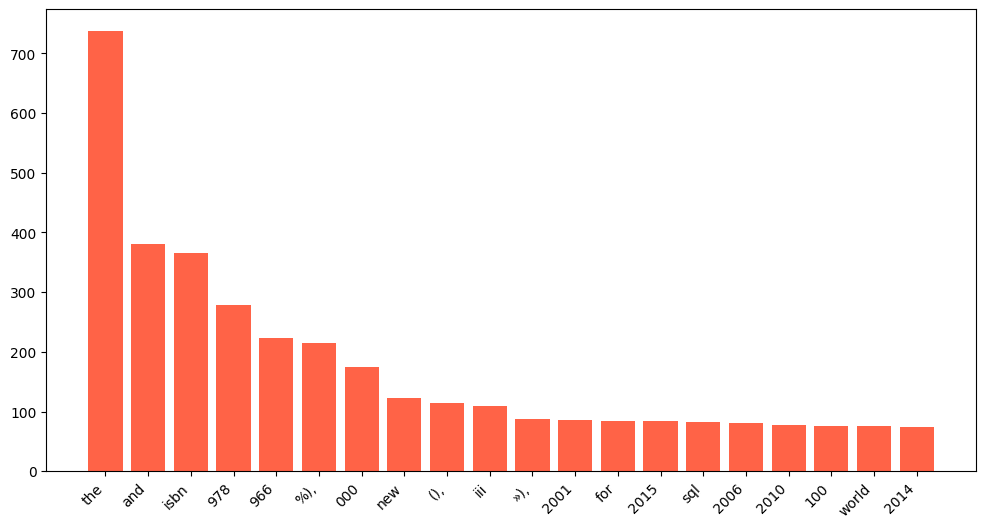

In [5]:
all_corpus_words = [token for sent in corpus for token in sent]
print("Кількість унікальних слів:", len(set(all_corpus_words)))

top_frequent = Counter(all_corpus_words).most_common(20)
print("20 найчастіших слів:", top_frequent)

terms, frequencies = zip(*top_frequent)
plt.figure(figsize=(12, 6))
plt.bar(terms, frequencies, color='tomato')
plt.xticks(rotation=45, ha='right')
plt.show()